In [ ]:
import pymysql
import pandas as pd

conn = pymysql.connect(
    host="127.0.0.1", port=3306,
    user="root", password="SUA_SENHA@",
    database="logistica_cd", connect_timeout=5
)

tabelas = ["clientes", "motoristas", "docas", "camaras_frias",
           "pedidos", "entregas", "itens_pedido"]

dfs = {t: pd.read_sql(f"SELECT * FROM {t}", conn) for t in tabelas}
conn.close()

for nome, df in dfs.items():
    print(f"{nome}: {df.shape[0]} linhas, {df.shape[1]} colunas")

C:\Users\Isabela\AppData\Local\Temp\ipykernel_23360\4253090328.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfs = {t: pd.read_sql(f"SELECT * FROM {t}", conn) for t in tabelas}


clientes: 15 linhas, 5 colunas
motoristas: 15 linhas, 4 colunas
docas: 18 linhas, 4 colunas
camaras_frias: 8 linhas, 6 colunas
pedidos: 0 linhas, 6 colunas
entregas: 0 linhas, 7 colunas
itens_pedido: 0 linhas, 7 colunas


C:\Users\Isabela\AppData\Local\Temp\ipykernel_23360\4253090328.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfs = {t: pd.read_sql(f"SELECT * FROM {t}", conn) for t in tabelas}
C:\Users\Isabela\AppData\Local\Temp\ipykernel_23360\4253090328.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfs = {t: pd.read_sql(f"SELECT * FROM {t}", conn) for t in tabelas}


In [ ]:
import pymysql
import pandas as pd

conn = pymysql.connect(
    host="127.0.0.1", port=3306,
    user="root", password="SUA_SENHA@",
    database="logistica_cd", connect_timeout=5
)

# 1. Taxa de entrega no prazo (o KPI principal de um CD)
q1 = """
SELECT
    COUNT(*) AS total_entregas,
    SUM(Entregue_No_Prazo) AS no_prazo,
    ROUND(SUM(Entregue_No_Prazo) / COUNT(*) * 100, 1) AS taxa_pct
FROM entregas
WHERE Data_Entrega IS NOT NULL
"""
print("=== TAXA DE ENTREGA NO PRAZO ===")
print(pd.read_sql(q1, conn))

# 2. Desempenho por motorista
q2 = """
SELECT
    m.Nome AS motorista,
    COUNT(e.id_Entregas) AS entregas,
    SUM(e.Entregue_No_Prazo) AS no_prazo,
    ROUND(SUM(e.Entregue_No_Prazo) / COUNT(e.id_Entregas) * 100, 1) AS taxa_pct
FROM entregas e
JOIN motoristas m ON m.id_Motorista = e.Motoristas_id_Motorista
WHERE e.Data_Entrega IS NOT NULL
GROUP BY m.Nome
ORDER BY taxa_pct ASC
"""
print("\n=== DESEMPENHO POR MOTORISTA ===")
print(pd.read_sql(q2, conn))

# 3. Faturamento por segmento de cliente
q3 = """
SELECT
    c.Segmento,
    COUNT(p.id_Pedido) AS pedidos,
    ROUND(SUM(p.Valor_Total), 2) AS faturamento,
    ROUND(AVG(p.Valor_Total), 2) AS ticket_medio
FROM pedidos p
JOIN clientes c ON c.id_Cliente = p.Clientes_id_Cliente
GROUP BY c.Segmento
ORDER BY faturamento DESC
"""
print("\n=== FATURAMENTO POR SEGMENTO ===")
print(pd.read_sql(q3, conn))

conn.close()

=== TAXA DE ENTREGA NO PRAZO ===


C:\Users\Isabela\AppData\Local\Temp\ipykernel_23360\2496165819.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql(q1, conn))


   total_entregas no_prazo taxa_pct
0               0     None     None

=== DESEMPENHO POR MOTORISTA ===


C:\Users\Isabela\AppData\Local\Temp\ipykernel_23360\2496165819.py:36: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql(q2, conn))


Empty DataFrame
Columns: [motorista, entregas, no_prazo, taxa_pct]
Index: []

=== FATURAMENTO POR SEGMENTO ===
Empty DataFrame
Columns: [Segmento, pedidos, faturamento, ticket_medio]
Index: []


C:\Users\Isabela\AppData\Local\Temp\ipykernel_23360\2496165819.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql(q3, conn))


In [ ]:
import pymysql
import random
from datetime import datetime, timedelta

random.seed(42)  # garante que o resultado seja sempre o mesmo

conn = pymysql.connect(
    host="127.0.0.1", port=3306,
    user="root", password="SUA_SENHA@",
    database="logistica_cd", connect_timeout=5
)
cur = conn.cursor()

# Produtos e a câmara onde cada um fica armazenado
PRODUTOS = [
    ("Carne Bovina Resfriada", 35.00, 1),
    ("Carne Suína Resfriada",  28.00, 1),
    ("Hortifruti Misto",       12.00, 2),
    ("Carne Bovina Congelada", 30.00, 3),
    ("Frango Congelado",       22.00, 4),
    ("Azeite Extra Virgem",    45.00, 5),
    ("Carne Seca",             38.00, 6),
    ("Carne para Exportação",  55.00, 7),
    ("Carne Reprocesso",       15.00, 8),
]

# Cada motorista tem um desempenho próprio (probabilidade de entregar no prazo)
CONFIABILIDADE = {i: round(random.uniform(0.70, 0.98), 2) for i in range(1, 16)}

inicio = datetime(2025, 1, 1)

for _ in range(400):
    dia = random.randint(0, 180)
    data_pedido = inicio + timedelta(days=dia, hours=random.randint(6, 18))
    mes = data_pedido.month

    id_cliente = random.randint(1, 15)

    # Monta os itens do pedido
    itens = random.sample(PRODUTOS, random.randint(1, 4))
    linhas_itens, peso_total, valor_total = [], 0, 0
    for nome, preco, camara in itens:
        qtd = random.randint(10, 120)
        peso = round(qtd * random.uniform(3, 6), 2)
        peso_total += peso
        valor_total += qtd * preco
        linhas_itens.append((nome, qtd, peso, preco, camara))

    # Status depende de quão recente é o pedido
    dias_atras = (datetime(2025, 6, 30) - data_pedido).days
    if dias_atras > 5:
        status = "entregue"
    else:
        status = random.choice(["separando", "expedido", "entregue"])

    cur.execute(
        "INSERT INTO pedidos (Data_Pedido, Status, Peso_Total_Kg, Valor_Total, Clientes_id_Cliente) "
        "VALUES (%s,%s,%s,%s,%s)",
        (data_pedido, status, round(peso_total, 2), round(valor_total, 2), id_cliente)
    )
    id_pedido = cur.lastrowid

    for nome, qtd, peso, preco, camara in linhas_itens:
        cur.execute(
            "INSERT INTO itens_pedido (produto, Quantidade, Peso_Kg, Valor_Unitario, "
            "Pedidos_id_Pedido, Camaras_Frias_id_Camara) VALUES (%s,%s,%s,%s,%s,%s)",
            (nome, qtd, peso, preco, id_pedido, camara)
        )

    # Só pedidos expedidos ou entregues geram registro de entrega
    if status in ("expedido", "entregue"):
        id_motorista = random.randint(1, 15)
        prazo = random.choice([1, 1, 2, 3])
        data_saida = data_pedido + timedelta(hours=random.randint(12, 36))

        chance = CONFIABILIDADE[id_motorista]
        if mes in (6, 12):       # meses de pico operam pior
            chance -= 0.15
        if peso_total > 500:     # cargas pesadas atrasam mais
            chance -= 0.10

        no_prazo = 1 if random.random() < chance else 0

        if status == "entregue":
            dias = prazo if no_prazo else prazo + random.randint(1, 4)
            data_entrega = data_saida + timedelta(days=dias, hours=random.randint(1, 8))
        else:
            data_entrega = None
            no_prazo = 0

        cur.execute(
            "INSERT INTO entregas (Data_Saida, Data_Entrega, Prazo_Dias, Entregue_No_Prazo, "
            "Pedidos_id_Pedido, Motoristas_id_Motorista) VALUES (%s,%s,%s,%s,%s,%s)",
            (data_saida, data_entrega, prazo, no_prazo, id_pedido, id_motorista)
        )

conn.commit()

cur.execute("SELECT COUNT(*) FROM pedidos");      print("pedidos:", cur.fetchone()[0])
cur.execute("SELECT COUNT(*) FROM entregas");     print("entregas:", cur.fetchone()[0])
cur.execute("SELECT COUNT(*) FROM itens_pedido"); print("itens:", cur.fetchone()[0])

conn.close()

pedidos: 400
entregas: 395
itens: 1026


In [ ]:
import pymysql
import pandas as pd
import warnings
warnings.filterwarnings("ignore")   # tira aquele aviso amarelo do pandas

conn = pymysql.connect(
    host="127.0.0.1", port=3306,
    user="root", password="SUA_SENHA@",
    database="logistica_cd", connect_timeout=5
)

print("=== 1. TAXA DE ENTREGA NO PRAZO (KPI GERAL) ===")
print(pd.read_sql("""
SELECT COUNT(*) AS entregas_concluidas,
       SUM(Entregue_No_Prazo) AS no_prazo,
       ROUND(SUM(Entregue_No_Prazo)/COUNT(*)*100, 1) AS taxa_pct
FROM entregas WHERE Data_Entrega IS NOT NULL
""", conn))

print("\n=== 2. DESEMPENHO POR MOTORISTA (piores primeiro) ===")
print(pd.read_sql("""
SELECT m.Nome AS motorista,
       COUNT(*) AS entregas,
       ROUND(SUM(e.Entregue_No_Prazo)/COUNT(*)*100, 1) AS taxa_pct
FROM entregas e
JOIN motoristas m ON m.id_Motorista = e.Motoristas_id_Motorista
WHERE e.Data_Entrega IS NOT NULL
GROUP BY m.Nome
HAVING COUNT(*) >= 10
ORDER BY taxa_pct ASC
""", conn))

print("\n=== 3. EVOLUÇÃO MENSAL ===")
print(pd.read_sql("""
SELECT DATE_FORMAT(e.Data_Saida, '%Y-%m') AS mes,
       COUNT(*) AS entregas,
       ROUND(SUM(e.Entregue_No_Prazo)/COUNT(*)*100, 1) AS taxa_pct
FROM entregas e
WHERE e.Data_Entrega IS NOT NULL
GROUP BY mes ORDER BY mes
""", conn))

print("\n=== 4. IMPACTO DO PESO DA CARGA ===")
print(pd.read_sql("""
SELECT CASE WHEN p.Peso_Total_Kg > 500 THEN 'Acima de 500kg'
            ELSE 'Ate 500kg' END AS faixa_peso,
       COUNT(*) AS entregas,
       ROUND(SUM(e.Entregue_No_Prazo)/COUNT(*)*100, 1) AS taxa_pct
FROM entregas e
JOIN pedidos p ON p.id_Pedido = e.Pedidos_id_Pedido
WHERE e.Data_Entrega IS NOT NULL
GROUP BY faixa_peso
""", conn))

conn.close()

=== 1. TAXA DE ENTREGA NO PRAZO (KPI GERAL) ===
   entregas_concluidas  no_prazo  taxa_pct
0                  390     273.0      70.0

=== 2. DESEMPENHO POR MOTORISTA (piores primeiro) ===
           motorista  entregas  taxa_pct
0   Leandro Ferreira        27      48.1
1   Fábio Nascimento        32      53.1
2    Marcelo Pereira        35      57.1
3       Marcos Silva        29      62.1
4      Ricardo Alves        31      64.5
5       Paulo Mendes        22      68.2
6       Roberto Lima        24      70.8
7     Thiago Barbosa        25      72.0
8        André Costa        25      76.0
9      Diego Martins        22      77.3
10  Rodrigo Carvalho        22      81.8
11     José Oliveira        24      83.3
12    Fernando Rocha        25      84.0
13      Carlos Souza        26      84.6
14    Eduardo Santos        21      85.7

=== 3. EVOLUÇÃO MENSAL ===
       mes  entregas  taxa_pct
0  2025-01        70      77.1
1  2025-02        59      72.9
2  2025-03        67      70.1
3  

In [ ]:
import pymysql, pandas as pd, warnings
warnings.filterwarnings("ignore")

conn = pymysql.connect(host="127.0.0.1", port=3306, user="root",
                       password="SUA_SENHA@", database="logistica_cd")

df_mes = pd.read_sql("""
SELECT DATE_FORMAT(Data_Saida, '%Y-%m') AS mes,
       COUNT(*) AS entregas,
       ROUND(SUM(Entregue_No_Prazo)/COUNT(*)*100, 1) AS taxa_pct
FROM entregas WHERE Data_Entrega IS NOT NULL
GROUP BY mes ORDER BY mes
""", conn)
conn.close()

print(df_mes.to_string(index=False))

    mes  entregas  taxa_pct
2025-01        70      77.1
2025-02        59      72.9
2025-03        67      70.1
2025-04        69      60.9
2025-05        61      75.4
2025-06        64      64.1


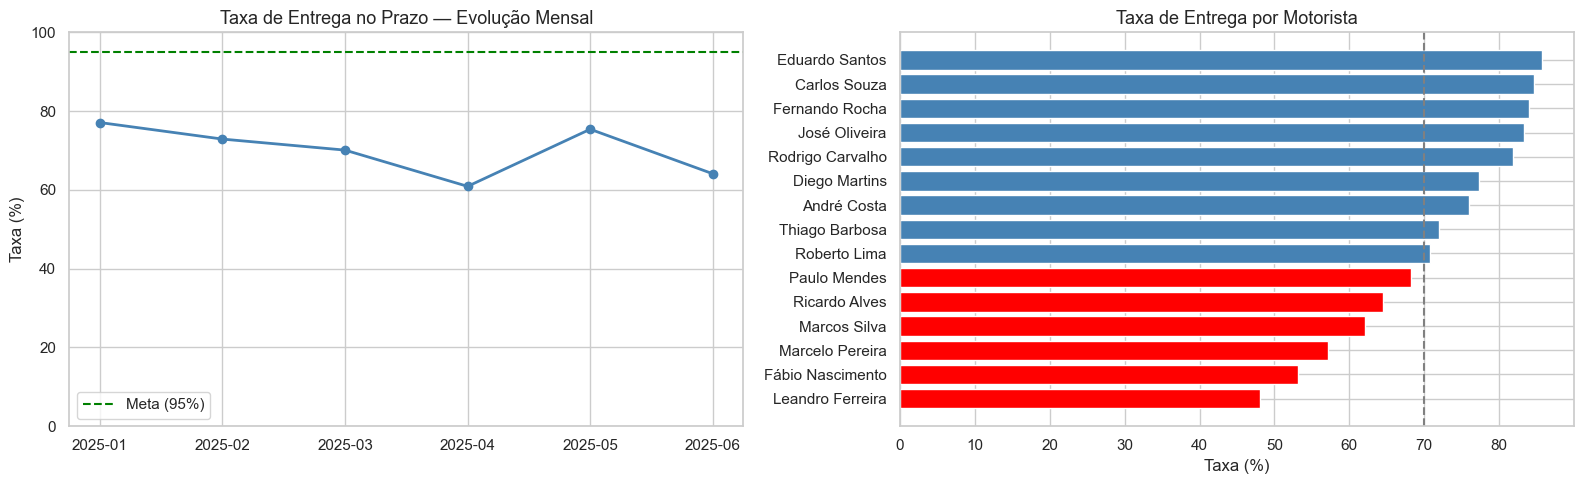

In [ ]:
import pymysql, pandas as pd, warnings
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

conn = pymysql.connect(host="127.0.0.1", port=3306, user="root",
                       password="SUA_SENHA@", database="logistica_cd")

df_mes = pd.read_sql("""
SELECT DATE_FORMAT(Data_Saida,'%Y-%m') AS mes,
       ROUND(SUM(Entregue_No_Prazo)/COUNT(*)*100,1) AS taxa_pct
FROM entregas WHERE Data_Entrega IS NOT NULL
GROUP BY mes ORDER BY mes
""", conn)

df_mot = pd.read_sql("""
SELECT m.Nome AS motorista,
       ROUND(SUM(e.Entregue_No_Prazo)/COUNT(*)*100,1) AS taxa_pct
FROM entregas e JOIN motoristas m ON m.id_Motorista=e.Motoristas_id_Motorista
WHERE e.Data_Entrega IS NOT NULL
GROUP BY m.Nome HAVING COUNT(*)>=10 ORDER BY taxa_pct
""", conn)
conn.close()

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Evolução mensal
ax[0].plot(df_mes['mes'], df_mes['taxa_pct'], marker='o', linewidth=2, color='steelblue')
ax[0].axhline(95, color='green', linestyle='--', label='Meta (95%)')
ax[0].set_title('Taxa de Entrega no Prazo — Evolução Mensal', fontsize=13)
ax[0].set_ylabel('Taxa (%)')
ax[0].set_ylim(0, 100)
ax[0].legend()

# Ranking de motoristas
cores = ['red' if t < 70 else 'steelblue' for t in df_mot['taxa_pct']]
ax[1].barh(df_mot['motorista'], df_mot['taxa_pct'], color=cores)
ax[1].axvline(70, color='gray', linestyle='--')
ax[1].set_title('Taxa de Entrega por Motorista', fontsize=13)
ax[1].set_xlabel('Taxa (%)')

plt.tight_layout()
plt.show()

In [ ]:
import pymysql, pandas as pd, numpy as np, warnings
warnings.filterwarnings("ignore")

conn = pymysql.connect(host="127.0.0.1", port=3306, user="root",
                       password="SUA_SENHA@", database="logistica_cd")

df = pd.read_sql("""
SELECT
    e.Entregue_No_Prazo        AS no_prazo,
    p.Peso_Total_Kg            AS peso,
    p.Valor_Total              AS valor,
    e.Prazo_Dias               AS prazo,
    MONTH(e.Data_Saida)        AS mes,
    DAYOFWEEK(e.Data_Saida)    AS dia_semana,
    m.Nome                     AS motorista,
    m.Veiculo                  AS veiculo,
    c.Segmento                 AS segmento,
    c.Estado                   AS estado,
    (SELECT COUNT(*) FROM itens_pedido i
     WHERE i.Pedidos_id_Pedido = p.id_Pedido) AS qtd_itens
FROM entregas e
JOIN pedidos   p ON p.id_Pedido  = e.Pedidos_id_Pedido
JOIN motoristas m ON m.id_Motorista = e.Motoristas_id_Motorista
JOIN clientes  c ON c.id_Cliente = p.Clientes_id_Cliente
WHERE e.Data_Entrega IS NOT NULL
""", conn)
conn.close()

print("Shape:", df.shape)
print("\nDistribuicao do alvo:")
print(df['no_prazo'].value_counts())
print(f"\nTaxa no prazo: {df['no_prazo'].mean()*100:.1f}%")
print("\nPrimeiras linhas:")
print(df.head())

Shape: (390, 11)

Distribuicao do alvo:
no_prazo
1    273
0    117
Name: count, dtype: int64

Taxa no prazo: 70.0%

Primeiras linhas:
   no_prazo    peso   valor  prazo  mes  dia_semana     motorista  \
0         0  955.79  3426.0      3    3           1  Carlos Souza   
1         1  475.39  4403.0      1    5           3  Carlos Souza   
2         1  568.88  3468.0      1    3           5  Carlos Souza   
3         1  806.83  6825.0      1    1           6  Carlos Souza   
4         0  594.45  6182.0      1    6           2  Carlos Souza   

        veiculo      segmento estado  qtd_itens  
0  Caminhão Baú        Varejo     CE          3  
1  Caminhão Baú        Varejo     SP          2  
2  Caminhão Baú  Food Service     MG          3  
3  Caminhão Baú     Hotelaria     SP          3  
4  Caminhão Baú        Varejo     SP          2  


In [8]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split

# Variáveis novas a partir das existentes
df['fim_semana']    = np.where(df['dia_semana'].isin([1, 7]), 1, 0)
df['carga_pesada']  = np.where(df['peso'] > 500, 1, 0)
df['prazo_apertado'] = np.where(df['prazo'] == 1, 1, 0)
df['valor_por_kg']  = (df['valor'] / df['peso']).round(2)

# Texto vira número (uma coluna 0/1 para cada categoria)
df_model = pd.get_dummies(
    df,
    columns=['motorista', 'veiculo', 'segmento', 'estado'],
    drop_first=True
)

X = df_model.drop('no_prazo', axis=1)
y = df_model['no_prazo']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Features: {X.shape[1]}")
print(f"Treino: {X_train.shape[0]} | Teste: {X_test.shape[0]}")
print(f"\nTaxa no prazo — treino: {y_train.mean()*100:.1f}% | teste: {y_test.mean()*100:.1f}%")

Features: 38
Treino: 292 | Teste: 98

Taxa no prazo — treino: 69.9% | teste: 70.4%


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

modelos = {
    'Regressão Logística': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42),
    'XGBoost':             XGBClassifier(random_state=42, eval_metric='logloss')
}

resultados = {}

for nome, algoritmo in modelos.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', algoritmo)
    ])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    resultados[nome] = {'pipeline': pipe, 'auc': roc_auc_score(y_test, y_prob)}

    print(f"=== {nome} ===")
    print(classification_report(y_test, y_pred,
          target_names=['Atrasado', 'No Prazo']))
    print(f"AUC-ROC: {resultados[nome]['auc']:.4f}\n")

=== Regressão Logística ===
              precision    recall  f1-score   support

    Atrasado       0.64      0.24      0.35        29
    No Prazo       0.75      0.94      0.83        69

    accuracy                           0.73        98
   macro avg       0.69      0.59      0.59        98
weighted avg       0.71      0.73      0.69        98

AUC-ROC: 0.5607

=== Random Forest ===
              precision    recall  f1-score   support

    Atrasado       0.50      0.03      0.06        29
    No Prazo       0.71      0.99      0.82        69

    accuracy                           0.70        98
   macro avg       0.60      0.51      0.44        98
weighted avg       0.65      0.70      0.60        98

AUC-ROC: 0.5852

=== XGBoost ===
              precision    recall  f1-score   support

    Atrasado       0.53      0.28      0.36        29
    No Prazo       0.75      0.90      0.82        69

    accuracy                           0.71        98
   macro avg       0.64     

In [ ]:
import pymysql
import random
from datetime import datetime, timedelta

random.seed(42)

conn = pymysql.connect(host="127.0.0.1", port=3306, user="root",
                       password="SUA_SENHA@", database="logistica_cd")
cur = conn.cursor()

PRODUTOS = [
    ("Carne Bovina Resfriada", 35.00, 1),
    ("Carne Suína Resfriada",  28.00, 1),
    ("Hortifruti Misto",       12.00, 2),
    ("Carne Bovina Congelada", 30.00, 3),
    ("Frango Congelado",       22.00, 4),
    ("Azeite Extra Virgem",    45.00, 5),
    ("Carne Seca",             38.00, 6),
    ("Carne para Exportação",  55.00, 7),
    ("Carne Reprocesso",       15.00, 8),
]

# Desempenho base de cada motorista — agora com separação clara
CONFIABILIDADE = {
     1: 0.92,  2: 0.88,  3: 0.90,  4: 0.55,  5: 0.85,
     6: 0.91,  7: 0.87,  8: 0.50,  9: 0.93, 10: 0.48,
    11: 0.52, 12: 0.89, 13: 0.58, 14: 0.86, 15: 0.94
}

# Estados distantes do CD (Araraquara/SP) entregam pior
DISTANTES = {"AM", "CE", "BA", "MS", "GO"}

inicio = datetime(2025, 1, 1)

for _ in range(800):
    dia = random.randint(0, 364)
    data_pedido = inicio + timedelta(days=dia, hours=random.randint(6, 18))
    mes = data_pedido.month

    id_cliente = random.randint(1, 15)
    cur.execute("SELECT Estado, Segmento FROM clientes WHERE id_Cliente = %s", (id_cliente,))
    estado, segmento = cur.fetchone()

    itens = random.sample(PRODUTOS, random.randint(1, 4))
    linhas, peso_total, valor_total = [], 0, 0
    for nome, preco, camara in itens:
        qtd = random.randint(10, 150)
        peso = round(qtd * random.uniform(3, 6), 2)
        peso_total += peso
        valor_total += qtd * preco
        linhas.append((nome, qtd, peso, preco, camara))

    dias_atras = (datetime(2025, 12, 31) - data_pedido).days
    status = "entregue" if dias_atras > 5 else random.choice(["separando", "expedido", "entregue"])

    cur.execute(
        "INSERT INTO pedidos (Data_Pedido, Status, Peso_Total_Kg, Valor_Total, Clientes_id_Cliente) "
        "VALUES (%s,%s,%s,%s,%s)",
        (data_pedido, status, round(peso_total,2), round(valor_total,2), id_cliente)
    )
    id_pedido = cur.lastrowid

    for nome, qtd, peso, preco, camara in linhas:
        cur.execute(
            "INSERT INTO itens_pedido (produto, Quantidade, Peso_Kg, Valor_Unitario, "
            "Pedidos_id_Pedido, Camaras_Frias_id_Camara) VALUES (%s,%s,%s,%s,%s,%s)",
            (nome, qtd, peso, preco, id_pedido, camara)
        )

    if status in ("expedido", "entregue"):
        id_motorista = random.randint(1, 15)
        prazo = random.choice([1, 1, 2, 3])
        data_saida = data_pedido + timedelta(hours=random.randint(12, 36))

        # ---- fatores que empurram a chance para cima ou para baixo ----
        chance = CONFIABILIDADE[id_motorista]

        if mes in (6, 12):                 chance -= 0.25   # pico
        if peso_total > 800:               chance -= 0.20
        elif peso_total > 500:             chance -= 0.10
        if prazo == 1:                     chance -= 0.20
        elif prazo == 3:                   chance += 0.08
        if estado in DISTANTES:            chance -= 0.15
        if data_saida.weekday() in (0, 4): chance -= 0.08   # segunda e sexta
        if len(linhas) >= 4:               chance -= 0.07   # separação mais longa

        chance = max(0.03, min(0.97, chance))
        no_prazo = 1 if random.random() < chance else 0

        if status == "entregue":
            dias = prazo if no_prazo else prazo + random.randint(1, 5)
            data_entrega = data_saida + timedelta(days=dias, hours=random.randint(1, 8))
        else:
            data_entrega, no_prazo = None, 0

        cur.execute(
            "INSERT INTO entregas (Data_Saida, Data_Entrega, Prazo_Dias, Entregue_No_Prazo, "
            "Pedidos_id_Pedido, Motoristas_id_Motorista) VALUES (%s,%s,%s,%s,%s,%s)",
            (data_saida, data_entrega, prazo, no_prazo, id_pedido, id_motorista)
        )

conn.commit()

for t in ("pedidos", "entregas", "itens_pedido"):
    cur.execute(f"SELECT COUNT(*) FROM {t}")
    print(f"{t}: {cur.fetchone()[0]}")

cur.execute("SELECT ROUND(AVG(Entregue_No_Prazo)*100,1) FROM entregas WHERE Data_Entrega IS NOT NULL")
print(f"taxa no prazo: {cur.fetchone()[0]}%")

conn.close()

pedidos: 1200
entregas: 1191
itens_pedido: 3046
taxa no prazo: 51.0%


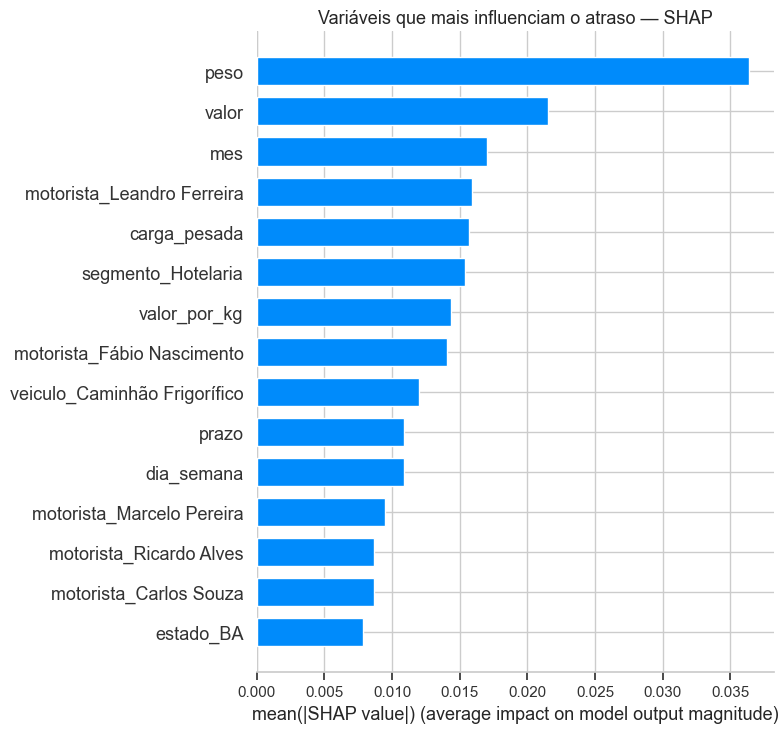

In [11]:
import shap
import matplotlib.pyplot as plt

# Random Forest foi o melhor — vamos explicar ele
pipe_rf = resultados['Random Forest']['pipeline']
modelo  = pipe_rf.named_steps['model']
scaler  = pipe_rf.named_steps['scaler']

# SHAP precisa dos dados na mesma escala que o modelo viu
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

explainer   = shap.TreeExplainer(modelo)
shap_values = explainer.shap_values(X_test_scaled)

# Em classificação binária o SHAP devolve os dois lados — pegamos a classe "No Prazo"
valores = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values

plt.figure(figsize=(10, 7))
shap.summary_plot(valores, X_test_scaled, plot_type="bar", show=False, max_display=15)
plt.title('Variáveis que mais influenciam o atraso — SHAP', fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
import pymysql

conn = pymysql.connect(host="127.0.0.1", port=3306, user="root",
                       password="SUA_SENHA@", database="logistica_cd")
cur = conn.cursor()

cur.execute("SET FOREIGN_KEY_CHECKS = 0")
for t in ("itens_pedido", "entregas", "pedidos"):
    cur.execute(f"TRUNCATE TABLE {t}")
cur.execute("SET FOREIGN_KEY_CHECKS = 1")
conn.commit()

cur.execute("SELECT COUNT(*) FROM pedidos")
print("pedidos:", cur.fetchone()[0])
conn.close()

pedidos: 0


In [ ]:
import pymysql
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

# 1. Puxa os dados do banco (com IDs e nomes para o dashboard)
conn = pymysql.connect(host="127.0.0.1", port=3306, user="root",
                       password="SUA_SENHA@", database="logistica_cd")

df = pd.read_sql("""
SELECT
    e.id_Entregas              AS id_entrega,
    p.id_Pedido                AS id_pedido,
    e.Data_Saida               AS data_saida,
    e.Entregue_No_Prazo        AS no_prazo,
    CAST(p.Peso_Total_Kg AS DECIMAL(10,2))  AS peso,
    CAST(p.Valor_Total   AS DECIMAL(10,2))  AS valor,
    e.Prazo_Dias               AS prazo,
    MONTH(e.Data_Saida)        AS mes,
    DAYOFWEEK(e.Data_Saida)    AS dia_semana,
    m.Nome                     AS motorista,
    m.Veiculo                  AS veiculo,
    c.Nome                     AS cliente,
    c.Segmento                 AS segmento,
    c.Estado                   AS estado,
    c.Cidade                   AS cidade,
    (SELECT COUNT(*) FROM itens_pedido i
     WHERE i.Pedidos_id_Pedido = p.id_Pedido) AS qtd_itens
FROM entregas e
JOIN pedidos    p ON p.id_Pedido    = e.Pedidos_id_Pedido
JOIN motoristas m ON m.id_Motorista = e.Motoristas_id_Motorista
JOIN clientes   c ON c.id_Cliente   = p.Clientes_id_Cliente
WHERE e.Data_Entrega IS NOT NULL
""", conn)
conn.close()

# Garante que peso e valor são número (MySQL devolve Decimal)
df['peso']  = pd.to_numeric(df['peso'])
df['valor'] = pd.to_numeric(df['valor'])

# 2. Feature engineering
df['fim_semana']     = np.where(df['dia_semana'].isin([1, 7]), 1, 0)
df['carga_pesada']   = np.where(df['peso'] > 500, 1, 0)
df['prazo_apertado'] = np.where(df['prazo'] == 1, 1, 0)
df['valor_por_kg']   = (df['valor'] / df['peso']).round(2)

# 3. Prepara X e y
X = pd.get_dummies(
    df.drop(columns=['id_entrega','id_pedido','data_saida','no_prazo','cliente','cidade']),
    columns=['motorista','veiculo','segmento','estado'], drop_first=True
)
y = df['no_prazo']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Treina o Random Forest
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=200, random_state=42))
])
pipe.fit(X_train, y_train)

# 5. Previsões para todas as entregas
df['prob_no_prazo'] = pipe.predict_proba(X)[:, 1].round(3)
df['previsao']      = pipe.predict(X)
df['risco_atraso']  = pd.cut(1 - df['prob_no_prazo'],
                             bins=[0, .3, .6, 1],
                             labels=['Baixo','Medio','Alto'])
df['status_real']   = np.where(df['no_prazo'] == 1, 'No Prazo', 'Atrasado')

# 6. Exporta no FORMATO BRASILEIRO (ponto-e-vírgula + vírgula decimal)
df.to_csv('entregas_powerbi.csv', index=False, sep=';', decimal=',', encoding='utf-8-sig')

print("✅ CSV salvo no formato brasileiro!")
print("Linhas:", len(df))
print("Faturamento real:", df['valor'].sum())
print("Ticket médio real:", round(df['valor'].mean(), 2))
print("\nDistribuição de risco:")
print(df['risco_atraso'].value_counts())

✅ CSV salvo no formato brasileiro!
Linhas: 390
Faturamento real: 2051591.0
Ticket médio real: 5260.49

Distribuição de risco:
risco_atraso
Baixo    252
Alto      88
Medio     50
Name: count, dtype: int64
